# Formative 3: Probability Distributions, Bayesian Probability and Gradient Descent
**Group 24** | Mathematics for Machine Learning | BSE, African Leadership University

**Members:** Philip Mganga, Methode, Nathanaella Hirwa

| Part | Topic | Lead |
|---|---|---|
| 1 | Expectation-Maximization (EM) on heights | Philip |
| 2 | Bayesian probability on IMDb reviews | Methode |
| 3 | Manual gradient descent (one iteration each) | All three |
| 4 | Gradient descent in code with SciPy | Nathanaella |

Each member also wrote or checked a slice of the other parts, so all three of us can explain every part.

## Part 1: Probability Distributions (EM)
### 1.1 Height data: inspect and plot

In [40]:
import csv, re, math, os
import urllib.request
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)

# Data setup: if the CSV files are missing, download them from our GitHub repo
RAW = "https://raw.githubusercontent.com/pmganga/group_24_probability/main/data/"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
for remote, local in [("galton_families.csv", "GaltonFamilies.csv"),
                      ("imdb_dataset.csv", "IMDB Dataset.csv")]:
    path = f"{DATA_DIR}/{local}"
    if not os.path.exists(path):
        print("downloading", local, "...")
        urllib.request.urlretrieve(RAW + remote, path)
print("data folder:", DATA_DIR, sorted(os.listdir(DATA_DIR)))

PARENT = "father"   # group choice: "father" or "mother" (compare with children)

data folder: data ['GaltonFamilies.csv', 'IMDB Dataset.csv']


In [41]:
def load_galton(path, parent=PARENT):
    """Return child heights and one parent height per family. Labels are dropped later."""
    with open(path, newline="") as f:
        rows = list(csv.DictReader(f))
    children = [float(r["childHeight"]) for r in rows]
    seen, parents = set(), []
    for r in rows:                      # one parent per family, so families are not counted twice
        if r["family"] not in seen:
            seen.add(r["family"])
            parents.append(float(r[parent]))
    return np.array(children), np.array(parents)

children, parents = load_galton(f"{DATA_DIR}/GaltonFamilies.csv")
heights = np.concatenate([children, parents])      # pooled and unlabeled, this is what EM sees
print(f"children: {len(children)}, {PARENT}s: {len(parents)}, pooled: {len(heights)}")
print(f"children mean {children.mean():.2f} in, std {children.std():.2f}")
print(f"{PARENT}s   mean {parents.mean():.2f} in, std {parents.std():.2f}")
print(f"pooled   mean {heights.mean():.2f} in, std {heights.std():.2f}")
print(f"missing values: {int(np.isnan(heights).sum())}")

children: 934, fathers: 205, pooled: 1139
children mean 66.75 in, std 3.58
fathers   mean 69.32 in, std 2.64
pooled   mean 67.21 in, std 3.57
missing values: 0


**What the numbers say.** Children and parents have close means and the two groups are very different in size,
so the pooled data forms one bumpy hill instead of two clean piles. The next plot shows the overlap.

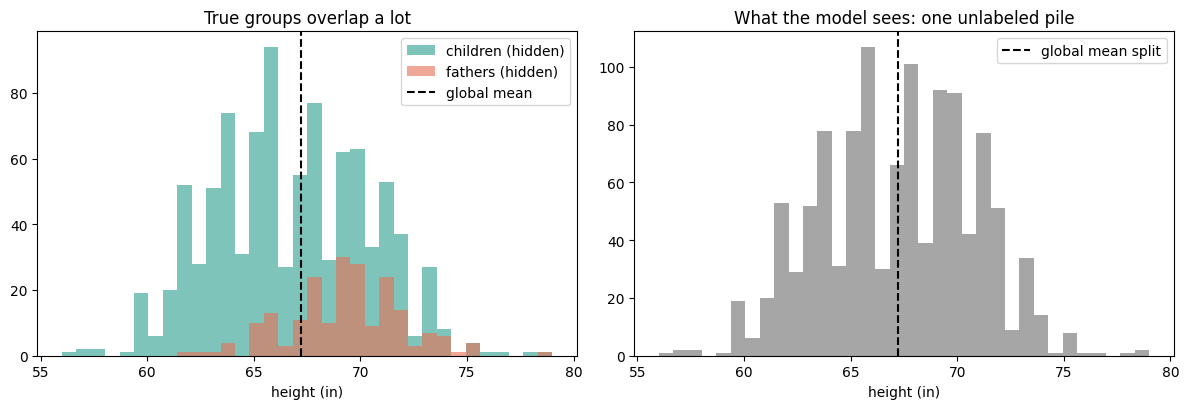

In [42]:
def plot_overlap(children, parents, heights, path):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    bins = np.linspace(heights.min(), heights.max(), 35)
    ax[0].hist(children, bins, alpha=.6, label="children (hidden)", color="#2a9d8f")
    ax[0].hist(parents, bins, alpha=.6, label=f"{PARENT}s (hidden)", color="#e76f51")
    ax[0].axvline(heights.mean(), color="k", ls="--", label="global mean")
    ax[0].set_title("True groups overlap a lot"); ax[0].set_xlabel("height (in)"); ax[0].legend()
    ax[1].hist(heights, bins, color="gray", alpha=.7)
    ax[1].axvline(heights.mean(), color="k", ls="--", label="global mean split")
    ax[1].set_title("What the model sees: one unlabeled pile"); ax[1].set_xlabel("height (in)"); ax[1].legend()
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

plot_overlap(children, parents, heights, "images/height_overlap.png")

Many children are taller than the global mean and many parents are shorter than it. A line at the mean would put
those points in the wrong pile, and it would give no sign of how unsure it is. That is the reason we use soft assignments (EM).

means [64.5  69.79] variances [5.94 5.5 ] weights [0.488 0.512]


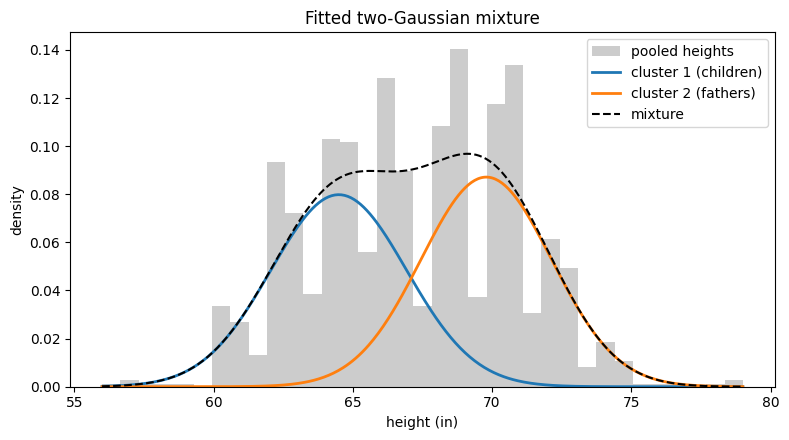

In [43]:
# Fitted mixture plot. This small EM is only here to draw the picture.
# This small EM is only for drawing the picture. The full EM with the tracking table is in section 1.2 below.
def gauss(x, mu, var):
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)

def quick_em(x, tol=1e-2, max_iter=200):
    mu = np.array([np.percentile(x, 25), np.percentile(x, 75)])
    var = np.array([x.var(), x.var()]); pi = np.array([.5, .5]); old = -np.inf
    for _ in range(max_iter):
        w = np.vstack([pi[k] * gauss(x, mu[k], var[k]) for k in range(2)])
        r = w / w.sum(axis=0)
        n = r.sum(axis=1)
        mu = (r * x).sum(axis=1) / n
        var = np.array([(r[k] * (x - mu[k]) ** 2).sum() / n[k] for k in range(2)])
        pi = n / len(x)
        ll = np.log(sum(pi[k] * gauss(x, mu[k], var[k]) for k in range(2))).sum()
        if abs(ll - old) < tol: break
        old = ll
    order = np.argsort(mu)
    return mu[order], var[order], pi[order]

mu, var, pi = quick_em(heights)
print("means", mu.round(2), "variances", var.round(2), "weights", pi.round(3))

xs = np.linspace(heights.min(), heights.max(), 400)
plt.figure(figsize=(8, 4.5))
plt.hist(heights, 35, density=True, color="gray", alpha=.4, label="pooled heights")
for k, name in enumerate(["cluster 1 (children)", f"cluster 2 ({PARENT}s)"]):
    plt.plot(xs, pi[k] * gauss(xs, mu[k], var[k]), lw=2, label=name)
plt.plot(xs, sum(pi[k] * gauss(xs, mu[k], var[k]) for k in range(2)), "k--", label="mixture")
plt.xlabel("height (in)"); plt.ylabel("density"); plt.title("Fitted two-Gaussian mixture")
plt.legend(); plt.tight_layout(); plt.savefig("images/fitted_mixture.png", dpi=150); plt.show()

### 1.2 EM algorithm, tracking table and live test
Our EM code is in `src/em.py`. It works in four steps.

1. **Start (initialisation).** Each group needs three values: a mean (μ), a variance (σ²) and a mixing weight (π, the share of people in that group). We start the two means at the 25th and 75th percentile of the heights, give both groups the variance of all the data, and set both weights to 0.5.
2. **E-step.** For every person, we use the Gaussian formula and the current values to work out how likely they are to belong to each group. These probabilities are called responsibilities. For each person they add up to 1.
3. **M-step.** We update the values using the responsibilities as weights. A person who is 90% child counts 0.9 towards the children's mean and 0.1 towards the fathers' mean. The same weighting gives the new variances and mixing weights.
4. **Stop or repeat.** We compute the log-likelihood, which measures how well the two curves fit the data. If it changed by less than 0.000001 since the last round, we stop. Otherwise we go back to step 2.

In [44]:
# Load our shared code from src/em.py (on Colab, download it from GitHub first)
import sys
if os.path.exists("../src/em.py"):          # running inside the repo
    ROOT = ".."
else:                                       # running on Colab
    if not os.path.exists("group_24_probability"):
        os.system("git clone -q https://github.com/pmganga/group_24_probability.git")
    ROOT = "group_24_probability"
sys.path.insert(0, ROOT)
from src.em import gaussian_pdf, fit_em, tracking_table, classify

In [45]:
params, history = fit_em(heights)
tracking_table(history)
print()
print(f"Converged at iteration {history[-1]['iteration']}, log-likelihood {history[-1]['log_likelihood']:.4f}")

Iteration    μ1 (Children)    μ2 (Fathers)       σ1²       σ2²       π1       π2   Log-Likelihood
-------------------------------------------------------------------------------------------------
0                  64.5000         70.0000   12.7241   12.7241   0.5000   0.5000       -3119.8222
1                  65.2205         69.2054    9.0603    8.4468   0.5011   0.4989       -3057.9135
2                  65.1609         69.2600    8.9420    8.1040   0.5005   0.4995       -3056.9719

Converged at iteration 319, log-likelihood -3046.9895


In [46]:
TEST_HEIGHT = 66   # the coach gives us this number during the presentation
classify(TEST_HEIGHT, params)

Height: 66
  P(Children | height) = 0.6236
  P(Fathers | height) = 0.3764


{'Children': np.float64(0.623604142968039),
 'Fathers': np.float64(0.376395857031961)}

In [47]:
for h in [60, 64, 66.75, 69.5, 75]:
    classify(h, params)

Height: 60
  P(Children | height) = 0.9965
  P(Fathers | height) = 0.0035
Height: 64
  P(Children | height) = 0.9098
  P(Fathers | height) = 0.0902
Height: 66.75
  P(Children | height) = 0.4511
  P(Fathers | height) = 0.5489
Height: 69.5
  P(Children | height) = 0.0532
  P(Fathers | height) = 0.9468
Height: 75
  P(Children | height) = 0.0002
  P(Fathers | height) = 0.9998


### 1.3 Should we split the data at the global mean?
**No.** The global mean of all heights is 67.21 inches. Cutting there and taking the average of each pile goes wrong in three ways.

1. **People end up in the wrong pile.** The groups overlap (see the plot in 1.1). Tall children land in the fathers' pile and short fathers land in the children's pile. Each pile's average and spread are then calculated from the wrong people.
2. **The cut gives no sense of doubt.** A person who is 66.75 inches tall gets a fixed label. EM gives them a 45% chance of being a child and a 55% chance of being a father, which shows we are not sure about them.
3. **The mean is only a fair cut-off if both groups are the same size and spread.** Ours are not: EM finds 43% children and 57% fathers, with different variances (5.30 and 6.04).

EM does not force each person into one pile. Each person counts towards both groups in proportion to their probabilities. This is called soft assignment, and it is why EM gives better estimates than cutting at the mean.

**Reading the table.** Row 0 is our starting guess. After one round the log-likelihood rises by about 62, the biggest jump of the whole run, and both variances shrink as the two curves move towards the real groups. After two rounds the changes are already small. EM keeps going until the log-likelihood stops changing, which happened at iteration 319.

The brief's table template says "Pros" and "Basketball Player". Our dataset compares fathers and children, so we use "Fathers".

## Part 2: Bayesian probability on IMDb reviews
**Goal:** estimate the chance that a review is positive when it contains a chosen keyword.

**Bayes' Theorem:**  P(Positive | word) = P(word | Positive) x P(Positive) / P(word)

**Group decision (one direction only):** we compute **P(Positive | word)** and never P(Negative | word).

**Allowed tools:** basic Python only. No machine learning libraries, no pandas.

### 2.1 Load the data

In [48]:
def load_reviews(path):
    csv.field_size_limit(10 ** 9)
    with open(path, encoding="utf-8", newline="") as f:
        rows = list(csv.DictReader(f))
    return [r["review"] for r in rows], [r["sentiment"] == "positive" for r in rows]

raw_reviews, is_positive = load_reviews(f"{DATA_DIR}/IMDB Dataset.csv")
print(len(raw_reviews), "reviews;", sum(is_positive), "positive,", len(is_positive) - sum(is_positive), "negative")
print(raw_reviews[0][:230], "...")

50000 reviews; 25000 positive, 25000 negative
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and un ...


### 2.1b Keep only distinct reviews
The file contains repeated reviews. A repeated review counts the same evidence twice and pulls every probability toward whatever that review says.
We keep the first copy of each review text and check that no text appears with two different labels.

In [49]:
def drop_duplicates(reviews, labels):
    seen, kept_r, kept_l, label_of, conflicts = set(), [], [], {}, 0
    for text, lab in zip(reviews, labels):
        if text in label_of and label_of[text] != lab:
            conflicts += 1                  # same text, different label (would need a decision)
        label_of.setdefault(text, lab)
        if text not in seen:
            seen.add(text); kept_r.append(text); kept_l.append(lab)
    return kept_r, kept_l, conflicts

n_before = len(raw_reviews)
raw_reviews, is_positive, conflicts = drop_duplicates(raw_reviews, is_positive)
print(f"before: {n_before} | duplicates removed: {n_before - len(raw_reviews)} | after: {len(raw_reviews)}")
print(f"same text with different labels: {conflicts}")
print(f"positive: {sum(is_positive)}, negative: {len(is_positive) - sum(is_positive)}")

before: 50000 | duplicates removed: 418 | after: 49582
same text with different labels: 0
positive: 24884, negative: 24698


### 2.2 Clean the text and tokenize
We need to check text data and remove unwanted text such as HTML tags.
The reviews contain `<br />` line breaks. Left in, they create a fake word `br` and can glue words together.

In [50]:
html_count = sum("<" in r for r in raw_reviews)
print(f"reviews that contain HTML tags: {html_count} of {len(raw_reviews)}")

def clean_review(text):
    text = re.sub(r"<[^>]+>", " ", text)       # 1. remove HTML tags such as <br />
    text = text.lower()                        # 2. lower case
    text = re.sub(r"[^a-z' ]", " ", text)      # 3. keep letters and apostrophes only
    return text

def tokenize(text):
    return clean_review(text).split()

before = Counter(w for r in raw_reviews[:2000] for w in r.lower().split())
after = Counter(w for r in raw_reviews[:2000] for w in tokenize(r))
print("token 'br' in 2000 reviews, raw split:", sum(c for w, c in before.items() if "br" == w.strip("<>/ ")), "| after cleaning:", after["br"])
print(tokenize(raw_reviews[0])[:25])

reviews that contain HTML tags: 28976 of 49582
token 'br' in 2000 reviews, raw split: 4532 | after cleaning: 0
['one', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', 'oz', 'episode', "you'll", 'be', 'hooked', 'they', 'are', 'right', 'as', 'this', 'is', 'exactly', 'what', 'happened']


**Counting rule.** A review either contains a word or it does not, so we store each review as a *set* of words.
"Contains the word" is the event used in the prior, the likelihood and the marginal. Using whole words (not substrings)
means "bad" does not match "badge".

In [51]:
word_sets = [set(tokenize(r)) for r in raw_reviews]
N = len(word_sets)
N_pos = sum(is_positive)
N_neg = N - N_pos

def count_word(word):
    """Return (reviews with word that are positive, reviews with word that are negative)."""
    pos = sum(1 for s, p in zip(word_sets, is_positive) if p and word in s)
    neg = sum(1 for s, p in zip(word_sets, is_positive) if (not p) and word in s)
    return pos, neg

### 2.3 Test candidate keywords before choosing
We tested 19 candidates and kept the ones with strong, clear signals and enough occurrences (so the estimates are stable).
Words like "great" and "bad" were rejected because they are weaker: they appear in many reviews of both types
(people write "not bad" and "not great").

In [52]:
candidates = ["excellent", "superb", "wonderful", "fantastic", "masterpiece", "brilliant", "perfect", "amazing", "great",
              "waste", "worst", "awful", "boring", "terrible", "horrible", "dull", "poor", "disappointing", "bad"]
print(f"{'word':<14}{'in pos':>8}{'in neg':>8}{'total':>8}{'P(Pos|word)':>14}")
for w in candidates:
    p, n = count_word(w)
    print(f"{w:<14}{p:>8}{n:>8}{p+n:>8}{p/(p+n):>14.3f}")

word            in pos  in neg   total   P(Pos|word)
excellent         2852     677    3529         0.808
superb            1024     171    1195         0.857
wonderful         2247     514    2761         0.814
fantastic         1077     267    1344         0.801
masterpiece        874     320    1194         0.732
brilliant         1575     491    2066         0.762
perfect           2030     610    2640         0.769
amazing           1672     474    2146         0.779
great             8420    4051   12471         0.675
waste              173    2328    2501         0.069
worst              406    3975    4381         0.093
awful              281    2568    2849         0.099
boring             588    2442    3030         0.194
terrible           380    2287    2667         0.142
horrible           321    1758    2079         0.154
dull               256    1124    1380         0.186
poor               733    2456    3189         0.230
disappointing      170     605     775        

**Final choice (4 positive, 4 negative)**

| Type | Keyword | Why we chose it |
|---|---|---|
| Positive | superb | Very strong positive signal, rarely used sarcastically |
| Positive | excellent | Common and clearly positive |
| Positive | wonderful | Common and clearly positive |
| Positive | fantastic | Strong signal, different style from the others |
| Negative | waste | Phrases like "waste of time" are almost always negative |
| Negative | worst | Superlative of a negative idea |
| Negative | awful | Strong negative word |
| Negative | boring | A very common complaint, with a bit more noise than the others |

We did not choose "great" or "bad": they are frequent but weak signals, so they would make weaker examples.

In [53]:
positive_keywords = ["superb", "excellent", "wonderful", "fantastic"]
negative_keywords = ["waste", "worst", "awful", "boring"]
keywords = positive_keywords + negative_keywords

### 2.4 Prior, likelihood, marginal and posterior
For each keyword:

* **Prior** P(Positive) = positive reviews / all reviews
* **Likelihood** P(word | Positive) = positive reviews containing the word / positive reviews
* **Marginal** P(word) by the law of total probability: P(word | Pos) P(Pos) + P(word | Neg) P(Neg).
  This is the fix for last semester's marginal feedback. We also count it directly as a cross-check, and the two must match.
* **Posterior** P(Positive | word) = likelihood x prior / marginal

**Zero-count handling.** If a word never appears in one class, the raw likelihood is 0 and the marginal can be 0
(division by zero). We add Laplace smoothing with alpha = 1 (add 1 to the count, add 2 to the class size).
We report the raw values for our keywords, because their counts are large and smoothing changes them by almost nothing,
and we show the zero-count case on a made-up word to prove the code handles it.

In [54]:
def bayes_for_word(word, alpha=0):
    pos, neg = count_word(word)
    prior_pos = N_pos / N
    prior_neg = N_neg / N
    like_pos = (pos + alpha) / (N_pos + 2 * alpha)      # P(word | Positive)
    like_neg = (neg + alpha) / (N_neg + 2 * alpha)      # P(word | Negative), only needed for the marginal
    marginal = like_pos * prior_pos + like_neg * prior_neg      # total probability
    direct = (pos + neg) / N                                    # direct count, cross-check
    posterior = like_pos * prior_pos / marginal if marginal > 0 else prior_pos   # fall back to prior
    return {"word": word, "prior": prior_pos, "likelihood": like_pos, "marginal": marginal,
            "marginal_direct": direct, "posterior": posterior, "count": pos + neg}

results = [bayes_for_word(w) for w in keywords]
for r in results:
    assert abs(r["marginal"] - r["marginal_direct"]) < 1e-12, r["word"]   # both ways agree
print("marginal by total probability matches the direct count for all keywords")

marginal by total probability matches the direct count for all keywords


In [55]:
print(f"Prior P(Positive) = {N_pos / N:.4f}\n")
header = f"{'Keyword':<11}{'Type':<10}{'Prior':>8}{'Likelihood':>12}{'Marginal':>10}{'Posterior':>11}{'Reviews':>9}"
print(header); print("-" * len(header))
for r in results:
    kind = "Positive" if r["word"] in positive_keywords else "Negative"
    print(f"{r['word']:<11}{kind:<10}{r['prior']:>8.4f}{r['likelihood']:>12.4f}{r['marginal']:>10.4f}{r['posterior']:>11.4f}{r['count']:>9}")

Prior P(Positive) = 0.5019

Keyword    Type         Prior  Likelihood  Marginal  Posterior  Reviews
-----------------------------------------------------------------------
superb     Positive    0.5019      0.0412    0.0241     0.8569     1195
excellent  Positive    0.5019      0.1146    0.0712     0.8082     3529
wonderful  Positive    0.5019      0.0903    0.0557     0.8138     2761
fantastic  Positive    0.5019      0.0433    0.0271     0.8013     1344
waste      Negative    0.5019      0.0070    0.0504     0.0692     2501
worst      Negative    0.5019      0.0163    0.0884     0.0927     4381
awful      Negative    0.5019      0.0113    0.0575     0.0986     2849
boring     Negative    0.5019      0.0236    0.0611     0.1941     3030


In [56]:
lines = ["| Keyword | Type | Prior P(Pos) | Likelihood P(word\\|Pos) | Marginal P(word) | Posterior P(Pos\\|word) |", "|---|---|---|---|---|---|"]
for r in results:
    kind = "Positive" if r["word"] in positive_keywords else "Negative"
    lines.append(f"| {r['word']} | {kind} | {r['prior']:.4f} | {r['likelihood']:.4f} | {r['marginal']:.4f} | {r['posterior']:.4f} |")
print("\n".join(lines))

| Keyword | Type | Prior P(Pos) | Likelihood P(word\|Pos) | Marginal P(word) | Posterior P(Pos\|word) |
|---|---|---|---|---|---|
| superb | Positive | 0.5019 | 0.0412 | 0.0241 | 0.8569 |
| excellent | Positive | 0.5019 | 0.1146 | 0.0712 | 0.8082 |
| wonderful | Positive | 0.5019 | 0.0903 | 0.0557 | 0.8138 |
| fantastic | Positive | 0.5019 | 0.0433 | 0.0271 | 0.8013 |
| waste | Negative | 0.5019 | 0.0070 | 0.0504 | 0.0692 |
| worst | Negative | 0.5019 | 0.0163 | 0.0884 | 0.0927 |
| awful | Negative | 0.5019 | 0.0113 | 0.0575 | 0.0986 |
| boring | Negative | 0.5019 | 0.0236 | 0.0611 | 0.1941 |


### 2.5 Zero-count check

In [57]:
for w in ["superb", "zzxqv"]:                      # a real word and a word that never appears
    raw = bayes_for_word(w, alpha=0)
    smooth = bayes_for_word(w, alpha=1)
    print(f"{w:<8} raw posterior {raw['posterior']:.4f} | smoothed posterior {smooth['posterior']:.4f}")
print("For the unseen word the raw marginal is 0, so the code falls back to the prior. No crash.")

superb   raw posterior 0.8569 | smoothed posterior 0.8563
zzxqv    raw posterior 0.5019 | smoothed posterior 0.5000
For the unseen word the raw marginal is 0, so the code falls back to the prior. No crash.


### 2.6 Interpretation: compare each posterior with the prior
The prior is about 0.50, so a word with no information would leave the posterior near 0.50. The distance from the prior is the evidence the word gives us.

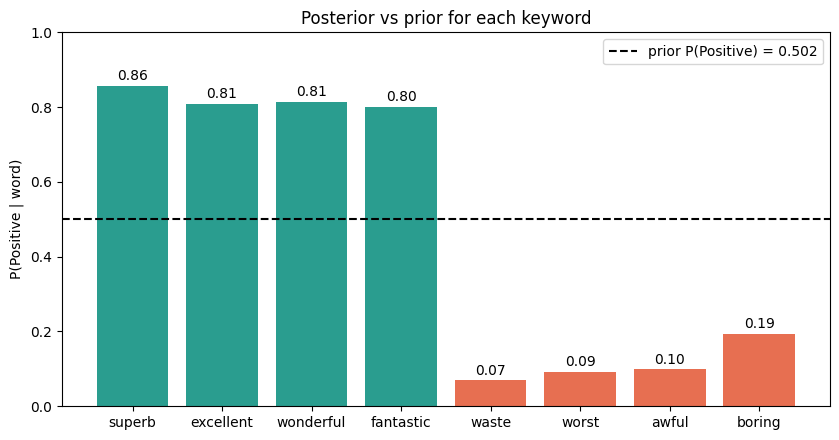

superb     raises the chance of a positive review by 35.5 points (0.50 -> 0.86)
excellent  raises the chance of a positive review by 30.6 points (0.50 -> 0.81)
wonderful  raises the chance of a positive review by 31.2 points (0.50 -> 0.81)
fantastic  raises the chance of a positive review by 29.9 points (0.50 -> 0.80)
waste      lowers the chance of a positive review by 43.3 points (0.50 -> 0.07)
worst      lowers the chance of a positive review by 40.9 points (0.50 -> 0.09)
awful      lowers the chance of a positive review by 40.3 points (0.50 -> 0.10)
boring     lowers the chance of a positive review by 30.8 points (0.50 -> 0.19)


In [58]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
vals = [r["posterior"] for r in results]
colors = ["#2a9d8f" if r["word"] in positive_keywords else "#e76f51" for r in results]
ax.bar(keywords, vals, color=colors)
ax.axhline(N_pos / N, color="k", ls="--", label=f"prior P(Positive) = {N_pos / N:.3f}")
for i, v in enumerate(vals):
    ax.text(i, v + .015, f"{v:.2f}", ha="center")
ax.set_ylim(0, 1); ax.set_ylabel("P(Positive | word)"); ax.set_title("Posterior vs prior for each keyword")
ax.legend(); plt.tight_layout(); plt.savefig("images/posterior_vs_prior.png", dpi=150); plt.show()

for r in results:
    shift = r["posterior"] - r["prior"]
    direction = "raises" if shift > 0 else "lowers"
    print(f"{r['word']:<10} {direction} the chance of a positive review by {abs(shift)*100:4.1f} points ({r['prior']:.2f} -> {r['posterior']:.2f})")

**Reading the result.**
* Every positive keyword pushes the posterior well above 0.50 and every negative keyword pushes it well below. The choices behave as expected.
* The negative words are slightly *stronger* evidence than the positive ones: "waste", "worst" and "awful" give posteriors under 0.10,
  while the positive words stay between about 0.80 and 0.86. People write negative reviews with harsher, more specific words.
* No word reaches 1.0 or 0.0. Reviews contain negations ("not boring") and quotes, so one word is evidence, not proof.
* Naive limits: we look at one word at a time and ignore word order. That is why this is Bayes' Theorem on a keyword, not a full classifier.

## Part 3: Manual gradient descent (check of the hand calculations)
The three hand iterations run as a relay. Iteration 1 starts from m = [-1, 2], b = 1, with learning rate alpha = 0.01. Each person starts from the previous person's result.
This cell only checks the handwritten numbers (iterations 1 and 2 here; Nathanaella adds iteration 3). Every step is shown.

In [59]:
X = np.array([[1., 3.], [4., 10.]]); y = np.array([5., 6.]); n = len(y); alpha = 0.01
m, b = np.array([-1., 2.]), 1.0

def step(m, b):
    y_hat = X @ m + b                    # predictions
    err = y_hat - y                      # errors
    mse = np.mean(err ** 2)
    dm = (2 / n) * X.T @ err             # chain rule: dJ/dyhat = 2/n * err, dyhat/dm = X
    db = (2 / n) * np.sum(err)           # chain rule: dyhat/db = 1
    return y_hat, err, mse, dm, db, m - alpha * dm, b - alpha * db

for it in (1, 2):
    y_hat, err, mse, dm, db, m_new, b_new = step(m, b)
    print(f"--- iteration {it} (start m={m}, b={b:.4f})")
    print(f"y_hat={y_hat}, errors={err}, MSE={mse:.4f}")
    print(f"dJ/dm={dm}, dJ/db={db:.4f}")
    print(f"new m={m_new}, new b={b_new:.4f}")
    m, b = m_new, b_new

--- iteration 1 (start m=[-1.  2.], b=1.0000)
y_hat=[ 6. 17.], errors=[ 1. 11.], MSE=61.0000
dJ/dm=[ 45. 113.], dJ/db=12.0000
new m=[-1.45  0.87], new b=0.8800
--- iteration 2 (start m=[-1.45  0.87], b=0.8800)
y_hat=[2.04 3.78], errors=[-2.96 -2.22], MSE=6.8450
dJ/dm=[-11.84 -31.08], dJ/db=-5.1800
new m=[-1.3316  1.1808], new b=0.9318


## Part 4: Gradient descent in code
We turn the hand calculations from Part 3 into Python. The model is y_hat = X m + b with
X = [[1, 3], [4, 10]], y = [5, 6], start m = [-1, 2], b = 1.
Every step is visible: predictions, errors, cost, gradient and the update.

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import approx_fprime

print("SciPy version:", scipy.__version__)

X = np.array([[1., 3.], [4., 10.]])      # data points, one row each
y = np.array([5., 6.])                   # targets
m_start = np.array([-1., 2.])            # initial m
b_start = 1.0                            # initial b

SciPy version: 1.16.3


### 4.1 Small, reusable functions
`theta = [m1, m2, b]` holds all three parameters in one vector, so one derivative call gives all three slopes.

In [61]:
def predict(X, m, b):
    """y_hat = X m + b (matrix multiplication, not a loop)."""
    return X @ m + b

def mse(y_hat, y):
    """Mean squared error J = (1/n) * sum (y_hat - y)^2."""
    return np.mean((y_hat - y) ** 2)

def cost(theta, X, y):
    """The equation we differentiate: J as a function of theta = [m1, m2, b]."""
    m, b = theta[:2], theta[2]
    return mse(predict(X, m, b), y)

def scipy_derivative(equation, point, *args):
    """Use SciPy to compute the derivative (gradient) of any equation at a point."""
    return approx_fprime(point, equation, np.sqrt(np.finfo(float).eps), *args)

def chain_rule_gradient(theta, X, y):
    """The same gradient from our Part 3 hand derivation, used only to check SciPy."""
    m, b = theta[:2], theta[2]
    error = predict(X, m, b) - y
    n = len(y)
    return np.append((2 / n) * X.T @ error, (2 / n) * error.sum())

def update(theta, gradient, learning_rate):
    """One gradient descent step: theta_new = theta - learning_rate * gradient."""
    return theta - learning_rate * gradient

### 4.2 Check SciPy's derivative against our hand derivation

In [62]:
theta0 = np.append(m_start, b_start)
g_scipy = scipy_derivative(cost, theta0, X, y)
g_hand = chain_rule_gradient(theta0, X, y)
print("SciPy gradient     :", g_scipy)
print("Chain rule gradient:", g_hand)
print("Largest difference :", np.abs(g_scipy - g_hand).max())
assert np.allclose(g_scipy, g_hand, atol=1e-4)

SciPy gradient     : [ 45.         113.00000095  12.        ]
Chain rule gradient: [ 45. 113.  12.]
Largest difference : 9.5367431640625e-07


### 4.3 Three updates, every step printed
Three updates, one for each member, matching the three handwritten iterations in Part 3.
The learning rate is 0.01.

In [63]:
def gradient_descent(theta, X, y, learning_rate, n_iter, verbose=False):
    """Run gradient descent. Returns the history of theta and the cost."""
    thetas, costs = [theta.copy()], []
    for i in range(1, n_iter + 1):
        m, b = theta[:2], theta[2]
        y_hat = predict(X, m, b)
        error = y_hat - y
        J = mse(y_hat, y)
        grad = scipy_derivative(cost, theta, X, y)
        new_theta = update(theta, grad, learning_rate)
        if verbose:
            print(f"--- iteration {i}")
            print(f"  m = {m.round(4)}, b = {b:.4f}")
            print(f"  predictions y_hat = {y_hat.round(4)}")
            print(f"  errors            = {error.round(4)}")
            print(f"  cost J            = {J:.4f}")
            print(f"  gradient dJ/dm = {grad[:2].round(4)}, dJ/db = {grad[2]:.4f}")
            print(f"  new m = {new_theta[:2].round(4)}, new b = {new_theta[2]:.4f}")
        costs.append(J)
        theta = new_theta
        thetas.append(theta.copy())
    costs.append(cost(theta, X, y))
    return np.array(thetas), np.array(costs)

LEARNING_RATE = 0.01
thetas3, costs3 = gradient_descent(theta0, X, y, LEARNING_RATE, 3, verbose=True)

--- iteration 1
  m = [-1.  2.], b = 1.0000
  predictions y_hat = [ 6. 17.]
  errors            = [ 1. 11.]
  cost J            = 61.0000
  gradient dJ/dm = [ 45. 113.], dJ/db = 12.0000
  new m = [-1.45  0.87], new b = 0.8800
--- iteration 2
  m = [-1.45  0.87], b = 0.8800
  predictions y_hat = [2.04 3.78]
  errors            = [-2.96 -2.22]
  cost J            = 6.8450
  gradient dJ/dm = [-11.84 -31.08], dJ/db = -5.1800
  new m = [-1.3316  1.1808], new b = 0.9318
--- iteration 3
  m = [-1.3316  1.1808], b = 0.9318
  predictions y_hat = [3.1426 7.4134]
  errors            = [-1.8574  1.4134]
  cost J            = 2.7238
  gradient dJ/dm = [3.7962 8.5618], dJ/db = -0.4440
  new m = [-1.3696  1.0952], new b = 0.9362


### 4.4 Why the learning rate matters

In [64]:
for lr in (0.1, 0.01):
    _, c = gradient_descent(theta0, X, y, lr, 3)
    print(f"learning rate {lr:<5} cost after 0, 1, 2, 3 updates: {np.round(c, 3)}")

learning rate 0.1   cost after 0, 1, 2, 3 updates: [6.10000000e+01 8.08970000e+03 1.11684377e+06 1.54230043e+08]
learning rate 0.01  cost after 0, 1, 2, 3 updates: [61.     6.845  2.724  2.39 ]


With 0.1 each step overshoots the minimum and the cost explodes, so 0.1 is too large for this data. With 0.01 the cost falls at every step.
The learning rate is the step size: the gradient gives the direction, and the learning rate decides how far to move.

### 4.5 Longer run, final values and predictions

In [65]:
N_LONG = 300
thetas, costs = gradient_descent(theta0, X, y, LEARNING_RATE, N_LONG)
final_m, final_b = thetas[-1][:2], thetas[-1][2]
final_pred = predict(X, final_m, final_b)
print(f"after {N_LONG} iterations")
print("final m =", final_m.round(4), " final b =", round(final_b, 4))
print("predictions with final m and b:", final_pred.round(4), " targets:", y)
print("final cost:", round(costs[-1], 6))

after 300 iterations
final m = [-2.0228  1.1007]  final b = 3.2308
predictions with final m and b: [4.5102 6.1471]  targets: [5. 6.]
final cost: 0.130758


### 4.6 Plots

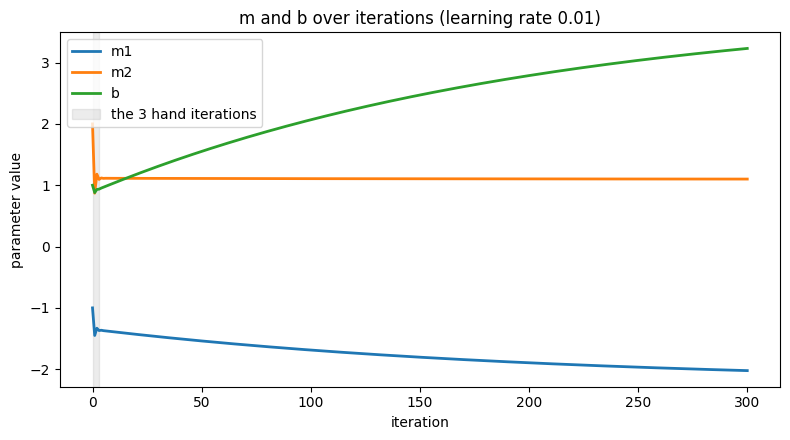

In [69]:
import os
os.makedirs("../images", exist_ok=True)
iters = np.arange(len(thetas))
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, name in enumerate(["m1", "m2", "b"]):
    ax.plot(iters, thetas[:, j], label=name, lw=2)
ax.axvspan(0, 3, color="gray", alpha=.15, label="the 3 hand iterations")
ax.set_xlabel("iteration"); ax.set_ylabel("parameter value")
ax.set_title("m and b over iterations (learning rate 0.01)"); ax.legend()
plt.tight_layout(); plt.savefig("../images/gd_parameters.png", dpi=150); plt.show()

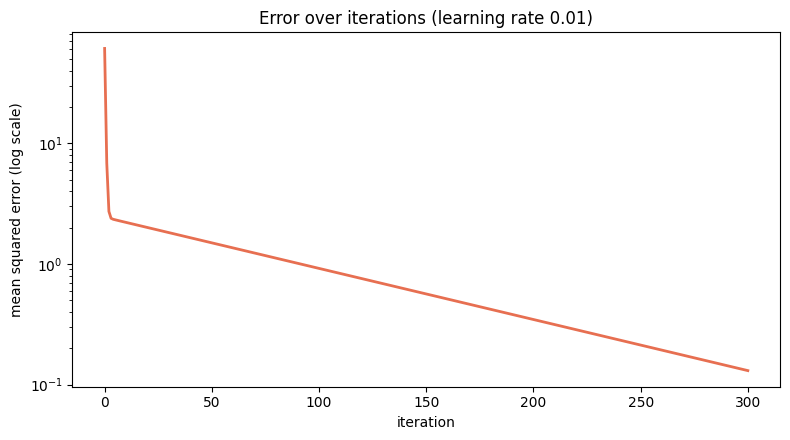

In [70]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(len(costs)), costs, color="#e76f51", lw=2)
ax.set_yscale("log")
ax.set_xlabel("iteration"); ax.set_ylabel("mean squared error (log scale)")
ax.set_title("Error over iterations (learning rate 0.01)")
plt.tight_layout(); plt.savefig("../images/gd_error.png", dpi=150); plt.show()

In [68]:
print("cost at iterations 0, 1, 2, 3:", np.round(costs[:4], 4))
print("cost is lower at every one of the first 100 steps:", bool(np.all(np.diff(costs[:100]) < 0)))

cost at iterations 0, 1, 2, 3: [61.      6.845   2.7238  2.3904]
cost is lower at every one of the first 100 steps: True


**Trend.** The cost falls at every step: 61.0, 6.845, 2.724, 2.390, and keeps falling. So m and b move in the direction that reduces the error.
The curves flatten as the gradient gets smaller, which is the expected shape.